In [1]:

def solution(brown, yellow):
    total = brown + yellow
    possible = []

    if yellow == 1:
        possible.append([1, 1])
    else:
        for i in range(1, yellow + 1):
            for j in range(i, yellow + 1):
                if i * j == yellow:
                    possible.append([i, j])

    for r, c in possible:
        tempa, tempb = c + 2, r + 2

        if tempa * tempb == total:
            return [tempa, tempb]


In [2]:

def solution(brown, yellow):
    total = brown + yellow

    for h in range(1, int(total ** 0.5) + 1):
        if total % h == 0:
            w = total // h

            if 2 * w + 2 * h - 4 == brown:
                return [w, h]


In [3]:
def solution(brown, yellow):
    for h in range(1,int(brown/2)):
        w = (brown + yellow) / h
        if w.is_integer():
            if 2 * h + 2 * w - 4 == brown and w >= h:
                return [w,h]


brown = 24
yellow = 24
solution(brown, yellow)

[8.0, 6]

In [4]:
def solution(n):
    dp = [0] * (n + 1)  # dp[i] = i칸까지 가는 방법의 수

    dp[1] = 1
    if n >= 2:
        dp[2] =2 

    for i in range(3, n+1):
        dp[i] = (dp[i-1]+dp[i-2]) % 1234567

    return dp[n]




## Percetron

In [5]:
import math

def sigmoid(z):
    return 1 / (1 + math.exp(-z))

def perceptron(inputs, weights, bias):
    # ① 가중합: Σ wᵢxᵢ + b
    z = sum(w*x for w, x in zip(weights, inputs)) + bias
    # ② 활성화 함수 통과
    return sigmoid(z)

# 입력 2개짜리 퍼셉트론 (뉴런 하나)
inputs  = [1.0, 2.0]
weights = [0.5, -1.0]
bias    = 0.5

out = perceptron(inputs, weights, bias)
print(f"출력: {out:.3f}")   # 0~1 사이 값
# z = 0.5*1 + (-1)*2 + 0.5 = -1.0 → sigmoid(-1) ≈ 0.269

출력: 0.269


In [6]:
# 계단 함수를 쓰는 원조 퍼셉트론으로 AND 게이트 만들기
def step(z):
    return 1 if z >= 0 else 0

def and_gate(x1, x2):
    w1, w2, b = 1.0, 1.0, -1.5   # 가중치 [1, 1], 편향 -1.5
    z = w1*x1 + w2*x2 + b          # ① 가중합
    return step(z)                 # ② 계단 함수 통과

print("x1 x2 |    z | AND")
for x1, x2 in [(0,0), (1,0), (0,1), (1,1)]:
    z = 1.0*x1 + 1.0*x2 - 1.5
    print(f" {x1}  {x2} | {z:+.1f} |  {step(z)}")
# (0,0)→-1.5→0, (1,0)→-0.5→0, (0,1)→-0.5→0, (1,1)→+0.5→1

x1 x2 |    z | AND
 0  0 | -1.5 |  0
 1  0 | -0.5 |  0
 0  1 | -0.5 |  0
 1  1 | +0.5 |  1


In [7]:
x = [1,2,3,4]
y = [3,5,7,9]

w,b = 0.0, 0.0
lr = 0.01
n = len(x)

for epoch in range(5000):
    y_pre = [w * xi + b for xi in x]
    error = [yp - yi for yp, yi in zip(y_pre, y)]

    # w의 변화량
    # Loss = 1/n sum(error ^2)
    # y_prep
    dw = 2 * sum(e * xi for e, xi in zip(error, x))/n
    
    db = 2 * sum(error)/n

    w -= lr * dw
    b -= lr * db
    print(w,b)


print(w,b)
print(error)

0.35000000000000003 0.12
0.6415000000000001 0.2201
0.8842700000000001 0.303623
1.0864483500000002 0.37333704
1.2548142455000002 0.4315478817
1.3950147145900003 0.480176211791
1.5117536968119503 0.52082195182568
1.6089495446988737 0.5548178279485689
1.6898662215966143 0.5832739941546539
1.7572225886493895 0.6071152031917301
1.8132834401923945 0.627111769695426
1.859935335678764 0.6439053622918978
1.8987497672123546 0.6580304882621216
1.9310357777173952 0.6699323901362615
1.9578837915529728 0.6799819534476665
1.9802021251476436 0.6884881248010646
1.9987474001354437 0.6957082560476611
2.014149877312744 0.7018567209199357
2.0269345596698356 0.7071120926358998
2.0375387710875654 0.71162312279969
2.0463267992844463 0.7155137217893179
2.0536020933023136 0.7188871073893093
2.059617423937501 0.7218292605764074
2.0645833473180555 0.7244118041680042
2.068675255011947 0.7266944007187414
2.0720392467242177 0.7287267499537692
2.0747970222178966 0.7305502526184829
2.077049956254288 0.7321993964552185

In [8]:
uv add scikit-learn
uv add seaborn

SyntaxError: invalid syntax (4062451519.py, line 1)

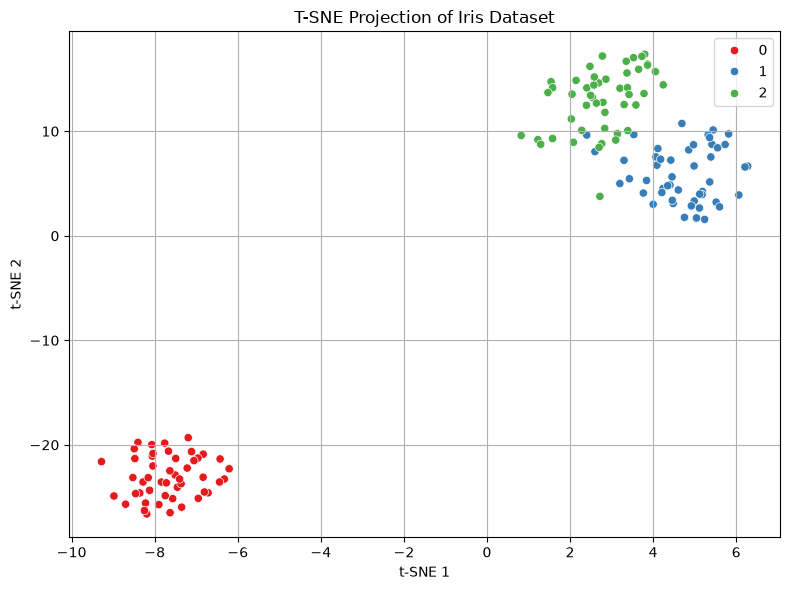

In [26]:
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 데이터 로드
iris = load_iris()
X = iris.data
y = iris.target

# 2. t-SNE 임베딩(2차원)
tsne = TSNE(n_components=2, random_state=42, init='random')
X_tsne = tsne.fit_transform(X)

# 3. 시각화
plt.figure(figsize = (8, 6))
sns.scatterplot(x=X_tsne[:,0], y= X_tsne[:,1], hue =y, palette ='Set1', legend='full')
plt.title("T-SNE Projection of Iris Dataset")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#!pip install umap-learn

error: Failed to add dependencies
  cause: No solution found when resolving dependencies for split (markers: python_full_version >= '3.12' and python_full_version < '3.14' and sys_platform == 'win32')
  cause: Because umpa-learn was not found in the package registry and your project depends on umpa-learn, we can conclude that your project's requirements are unsatisfiable.

hint: If you want to add the package regardless of the failed resolution, provide the `--frozen` flag to skip locking and syncing


c:\code\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


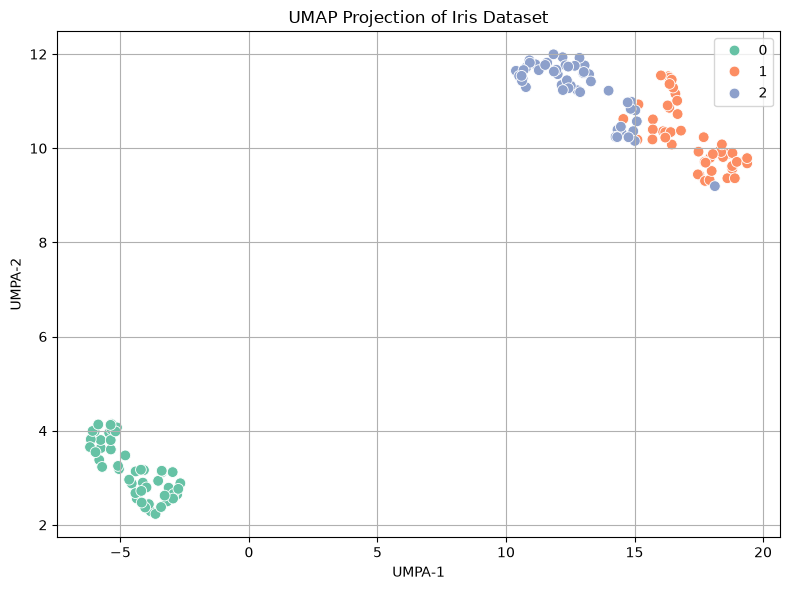

In [29]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.datasets import load_iris

# 1. 데이터 로드

iris = load_iris()
X = pd.DataFrame(iris.data, columns = iris.feature_names)
y = iris.target

# 2. UMAP 임베딩(2차원)
reducer = umap.UMAP(n_neighbors = 15, min_dist = 0.1, random_state = 42, init='random')
X_umap = reducer.fit_transform(X)

# 3. 시각화
plt.figure(figsize = (8,6))
sns.scatterplot(x=X_umap[:,0], y=X_umap[:,1], hue = y, palette = 'Set2', s = 60)
plt.title("UMAP Projection of Iris Dataset")
plt.xlabel("UMPA-1")
plt.ylabel("UMPA-2")
plt.grid(True)
plt.tight_layout()
plt.show()

In [47]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
# 오토 인코더 모델 
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64,12),
            nn.ReLU(),
            nn.Linear(12,3) # 압축된 표현
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(3,12),
            nn.ReLU(),
            nn.Linear(12,64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid() # 픽셀 각각이 0 과 1 사이 값을 가져야 하므로
            )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
        
# 데이터 로딩
transform = transforms.Compose([
    transforms.ToTensor(), # 텐서로 변환
    # transforms.Normalize((0.5,), (0.5,)) # 정규화
])
train_dataset= datasets.MNIST(root='./data', train = True, transform = transform, download = True)
train_loader =DataLoader(dataset = train_dataset, batch_size = 64, shuffle = True)

# 모델, 손실 함수 및 옵티마이저 초기화
model = Autoencoder()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)

# 훈련 과정
num_epochs = 20
losses = []
for epoch in range(num_epochs):
    for data in train_loader:
        img, _ = data # 레이블은 사용하지 않습니다.
        img = img.view(img.size(0), -1)
        # 순전파
        output = model(img)
        loss = criterion(output, img)

        # 역전파
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    losses.append(loss.item())
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')
print("training complted")

Epoch [1/20], Loss: 0.0463
Epoch [2/20], Loss: 0.0402
Epoch [3/20], Loss: 0.0345
Epoch [4/20], Loss: 0.0407
Epoch [5/20], Loss: 0.0305
Epoch [6/20], Loss: 0.0335
Epoch [7/20], Loss: 0.0296
Epoch [8/20], Loss: 0.0333
Epoch [9/20], Loss: 0.0351
Epoch [10/20], Loss: 0.0318
Epoch [11/20], Loss: 0.0300
Epoch [12/20], Loss: 0.0355
Epoch [13/20], Loss: 0.0331
Epoch [14/20], Loss: 0.0355
Epoch [15/20], Loss: 0.0322
Epoch [16/20], Loss: 0.0327
Epoch [17/20], Loss: 0.0312
Epoch [18/20], Loss: 0.0317
Epoch [19/20], Loss: 0.0262
Epoch [20/20], Loss: 0.0298
training complted


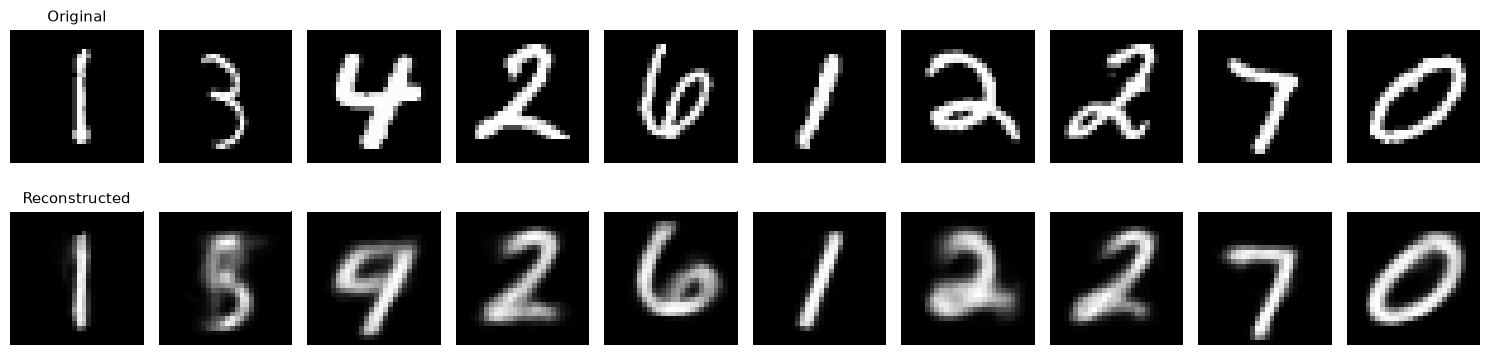

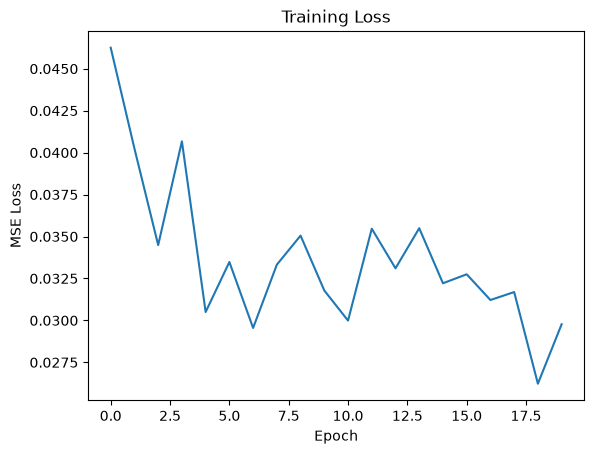

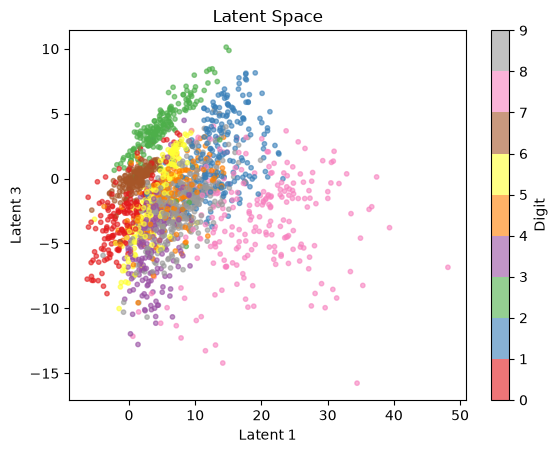

In [49]:
import matplotlib.pyplot as plt

# 1 결과 비교 시각화 
model.eval()
with torch.no_grad():
    test_iter = iter(train_loader)
    sample, _ = next(test_iter)
    sample_flat = sample.view(sample.size(0), -1)
    reconstructed = model(sample_flat)

n = 10 # 표시할 이미지 개수
plt.figure(figsize = (15, 4))
for i in range(n):
    # 원본
    ax = plt.subplot(2, n, i+ 1)
    plt.imshow(sample[i][0].cpu().numpy(), cmap='gray')
    ax.axis('off')
    if i == 0:
        ax.set_title('Original', fontsize=11)
    # 복원된 이미지
    ax = plt.subplot(2, n, i+ 1 + n)
    plt.imshow(reconstructed[i].view(28,28).cpu().numpy(), cmap='gray')
    ax.axis('off')
    if i == 0:
        ax.set_title('Reconstructed', fontsize=11)


plt.tight_layout()
plt.show()





plt.plot(losses)
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('Training Loss'); plt.show()

encoded_list, labels_list = [], []
count = 0
with torch.no_grad():
    for img, label in train_loader:
        z = model.encoder(img.view(img.size(0), -1))
        encoded_list.append(z)
        labels_list.append(label)
        if count >= 2000:  # 2000개 샘플만
            break

z = torch.cat(encoded_list)[:2000].cpu().numpy()
y = torch.cat(labels_list)[:2000].cpu().numpy()

plt.scatter(z[:, 0], z[:, 2], c=y, cmap='Set1', s=10, alpha=0.6)
plt.xlabel('Latent 1'); plt.ylabel('Latent 3')
plt.colorbar(label='Digit')
plt.title('Latent Space'); plt.show()

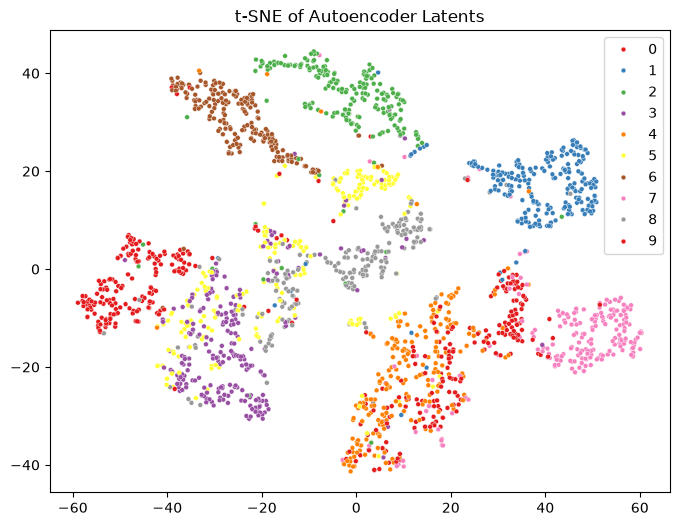

In [50]:
from sklearn.manifold import TSNE
import seaborn as sns

z, labels_list = [], []
count = 0
with torch.no_grad():
    for img, label in train_loader:
        z_code = model.encoder(img.view(img.size(0), -1))
        z.append(z_code)
        labels_list.append(label)
        count += img.size(0)
        if count >= 2000:
            break

z = torch.cat(z)[:2000].cpu().numpy()
y = torch.cat(labels_list)[:2000].cpu().numpy()

z_tsne = TSNE(n_components=2, random_state=42, init='pca').fit_transform(z)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=z_tsne[:, 0], y=z_tsne[:, 1], hue=y, palette='Set1', s=12, legend='full')
plt.title('t-SNE of Autoencoder Latents')
plt.show()

In [1]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# MediaPipe 얼굴 감지 초기화
mp_face_detection = mp.solutions.face_detection
mp_drawing = mp.solutions.drawing_utils

# webcam
cap = cv2.VideoCapture(0)

with mp_face_detection.FaceDetection(model_selection=0, min_detection_confidence=0.5) as face_detection:
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            print('카메라에서 프레임을 가져올 수 없습니다.')
            break

        # 이미지 전처리
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = face_detection.process(image)

        # 결과 표시
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
        if results.detections:
            for detection in results.detections:
                mp_drawing.draw_detection(image, detection)

        cv2.imshow('MediaPipe 얼굴 인식', image)

        if cv2.waitKey(5) & 0xFF == 27:  # esc 로 종료
            break

cap.release()
cv2.destroyAllWindows()


c:\code\.venv\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


## Mediapipe 얼굴 특징(랜드마크) 감지

In [2]:
import cv2
import mediapipe as mp

# MediaPipe 얼굴 랜드마크 모듈 초기화
mp_face_mesh = mp.solutions.face_mesh
mp_drawing = mp.solutions.drawing_utils
drawing_spec = mp_drawing.DrawingSpec(thickness=1, circle_radius=1)

# 웹캠 열기
cap = cv2.VideoCapture(0)

with mp_face_mesh.FaceMesh(
    static_image_mode=False,
    max_num_faces=1,
    refine_landmarks=True,  # 눈/입/홍채 디테일 향상
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
) as face_mesh:
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            print('카메라에서 프레임을 가져올 수 없습니다.')
            break

        # 이미지 전처리
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image.flags.writeable = False
        results = face_mesh.process(image)

        # 결과 표시
        image.flags.writeable = True
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
        if results.multi_face_landmarks:
            for face_landmarks in results.multi_face_landmarks:
                mp_drawing.draw_landmarks(
                    image=image,
                    landmark_list=face_landmarks,
                    connections=mp_face_mesh.FACEMESH_TESSELATION,
                    landmark_drawing_spec=None,
                    connection_drawing_spec=drawing_spec
                )
        cv2.imshow('Mediapipe 얼굴 특징 감지', image)

        if cv2.waitKey(5) & 0xFF == 27:  # esc 키로 종료
            break

cap.release()
cv2.destroyAllWindows()


## Mediapipe 포즈(동작) 인식

In [5]:
import cv2
import mediapipe as mp

# mediapipe pose 모듈 초기화
mp_pose = mp.solutions.pose
mp_drawing = mp.solutions.drawing_utils

# webcam
cap = cv2.VideoCapture(0)

with mp_pose.Pose(
    static_image_mode=False,
    model_complexity=1,
    enable_segmentation=False,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
) as pose:
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            print('카메라에서 프레임을 가져올 수 없습니다.')
            break

        # 이미지 전처리
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image.flags.writeable = False
        results = pose.process(image)

        # 결과 표시
        image.flags.writeable = True
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
        if results.pose_landmarks:
            mp_drawing.draw_landmarks(
                image, results.pose_landmarks, mp_pose.POSE_CONNECTIONS
            )
        cv2.imshow('MediaPipe 동작(포즈) 인식', image)

        if cv2.waitKey(5) & 0xFF == 27:  # ESC 키로 종료
            break

cap.release()
cv2.destroyAllWindows()


c:\code\.venv\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


## Mediapipe 손 랜드마크 인식

In [7]:
import cv2
import mediapipe as mp

# mediapipe hands 모듈 초기화
mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils

# webcam
cap = cv2.VideoCapture(0)

with mp_hands.Hands(
    static_image_mode=False,
    max_num_hands=2,
    model_complexity=1,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
) as hands:
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            print('카메라에서 프레임을 가져올 수 없습니다.')
            break

        # 이미지 전처리
        image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image.flags.writeable = False
        results = hands.process(image)

        # 결과 표시
        image.flags.writeable = True
        image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
        if results.multi_hand_landmarks:
            for hand_landmarks in results.multi_hand_landmarks:
                mp_drawing.draw_landmarks(
                    image, hand_landmarks, mp_hands.HAND_CONNECTIONS
                )
        cv2.imshow('MediaPipe 손 랜드마크 인식', image)

        if cv2.waitKey(5) & 0xFF == 27:  # ESC 키로 종료
            break

cap.release()
cv2.destroyAllWindows()


c:\code\.venv\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


In [10]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import numpy as np

# 모델 경로 설정 (mediapipe selfie segmentation 모델 필요)
model_path = "selfie_segmenter.tflite"

# 세분화 옵션 설정
base_options = python.BaseOptions(model_asset_path = model_path)
options = vision.ImageSegmenterOptions(
    base_options = base_options, output_category_mask = True
)
segmenter = vision.ImageSegmenter.create_from_options(options)


# webcam
cap = cv2.VideoCapture(0)

while cap.isOpened():
    success, frame = cap.read()
    if not success:
        print('카메라에서 프레임을 가져올 수 없습니다.')
        break

    # 세분화 수행
    image = mp.Image(image_format = mp.ImageFormat.SRGB, data = frame)
    result = segmenter.segment(image)
    mask = result.category_mask.numpy_view()

    # 마스크를 컬러로 변환
    condition = mask > 0.3 # 사람 영역 마스킹
    bg = frame.copy()
    bg[:] = (0,0, 225) # red bg
    segmented = np.where(condition[..., None], frame, bg)

    cv2.imshow('Mediapipe 이미 세분화', segmented )

    



    if cv2.waitKey(5) & 0xFF == 27:  # ESC 키로 종료
        break

cap.release()
cv2.destroyAllWindows()


RuntimeError: Unable to open file at c:\code\.venv\Lib\site-packages/c:\code\src\code\Oct_2026\Oct19\selfie_segmenter.tflite, errno=22

## Mediapipe 이미지 세분화(Selfie Segmentation)

In [ ]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import numpy as np
import os, urllib.request

# 모델 경로 설정 (mediapipe selfie segmentation 모델 / 최초 1회 다운로드)
model_path = 'selfie_segmenter.tflite'
if not os.path.exists(model_path):
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/mediapipe-models/image_segmenter/selfie_segmenter/float16/latest/selfie_segmenter.tflite',
        model_path
    )

# 세분화 옵션 설정
base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.ImageSegmenterOptions(
    base_options=base_options,
    output_category_mask=True,
    running_mode=vision.RunningMode.VIDEO  # 웹캠(동영상) 모드
)
segmenter = vision.ImageSegmenter.create_from_options(options)

# webcam
cap = cv2.VideoCapture(0)

while cap.isOpened():
    success, frame = cap.read()
    if not success:
        print('카메라에서 프레임을 가져올 수 없습니다.')
        break

    # 세분화 수행 (동영상 모드: 프레임별 타임스탬프 필요)
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = segmenter.segment_for_video(image, int(cap.get(cv2.CAP_PROP_POS_MSEC)))
    mask = result.category_mask.numpy_view()

    # 마스크를 컬러로 변환
    condition = mask > 0  # 사람 영역 마스킹 (category_mask는 0/1 값)
    bg = frame.copy()
    bg[:] = (0, 0, 225)  # red bg
    segmented = np.where(condition[..., None], frame, bg)

    cv2.imshow('Mediapipe 이미지 세분화', segmented)

    if cv2.waitKey(5) & 0xFF == 27:  # ESC 키로 종료
        break

cap.release()
cv2.destroyAllWindows()


RuntimeError: Unable to open file at c:\code\.venv\Lib\site-packages/c:\code\src\code\Oct_2026\Oct19\selfie_segmenter.tflite, errno=22